# What Drives the Price of a Used Car?

**Goal:** Identify which vehicle characteristics most strongly influence used-car prices, and translate that into practical inventory advice for a used car dealership.

**Process:** This notebook follows the CRISP-DM framework:
1. Business Understanding
2. Data Understanding
3. Data Preparation
4. Exploratory Data Analysis
5. Modeling
6. Evaluation
7. Findings, Recommendations and Next Steps (Deployment)

## 1. Business Understanding

A used car dealership wants to fine-tune its inventory. The practical question is:

> **Which attributes of a used car (age, mileage, brand, condition, drivetrain, etc.) do consumers value most, and how much does each one move the price?**

**What a good answer looks like**
- A ranked list of the factors that matter most for price, with an estimated size of each effect.
- A predictive model that is accurate enough to be trusted for pricing and buying decisions.
- Plain-language recommendations on what to stock, what to avoid, and what to pay for at auction or trade-in.

**Data science framing:** supervised **regression** problem. Target = `price`, features = vehicle attributes. We use interpretable linear models (to quantify effects) and a more flexible model (to check how much predictive power the linear models leave on the table).

**Evaluation metric:** *RMSE* (root mean squared error, in dollars) is the primary metric, with *MAE* and *R²* as supporting metrics.
- RMSE is in the same units as price, so a dealer can read it as "typical pricing error", and it penalizes large mispricings (the costly ones for a dealership) more than small ones.
- MAE is less sensitive to outliers and gives the "average miss".
- R² tells us what share of price variation the model explains.

## 2. Data Understanding

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42
pd.options.display.float_format = "{:,.2f}".format

Matplotlib is building the font cache; this may take a moment.


In [2]:
df_raw = pd.read_csv("../data/vehicles.csv")
print(f"Rows: {df_raw.shape[0]:,}   Columns: {df_raw.shape[1]}")
df_raw.head()

Rows: 426,880   Columns: 18


,id,region,price,year,manufacturer,model,condition,cylinders,fuel,odometer,title_status,transmission,VIN,drive,size,type,paint_color,state
0,7222695916,prescott,6000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,az
1,7218891961,fayetteville,11900,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ar
2,7221797935,florida keys,21000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,fl
3,7222270760,worcester / central MA,1500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ma
4,7210384030,greensboro,4900,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,nc


In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 426880 entries, 0 to 426879
Data columns (total 18 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   id            426880 non-null  int64  
 1   region        426880 non-null  str    
 2   price         426880 non-null  int64  
 3   year          425675 non-null  float64
 4   manufacturer  409234 non-null  str    
 5   model         421603 non-null  str    
 6   condition     252776 non-null  str    
 7   cylinders     249202 non-null  str    
 8   fuel          423867 non-null  str    
 9   odometer      422480 non-null  float64
 10  title_status  418638 non-null  str    
 11  transmission  424324 non-null  str    
 12  VIN           265838 non-null  str    
 13  drive         296313 non-null  str    
 14  size          120519 non-null  str    
 15  type          334022 non-null  str    
 16  paint_color   296677 non-null  str    
 17  state         426880 non-null  str    
dtypes: float64(2), 

### 2.1 Missing values

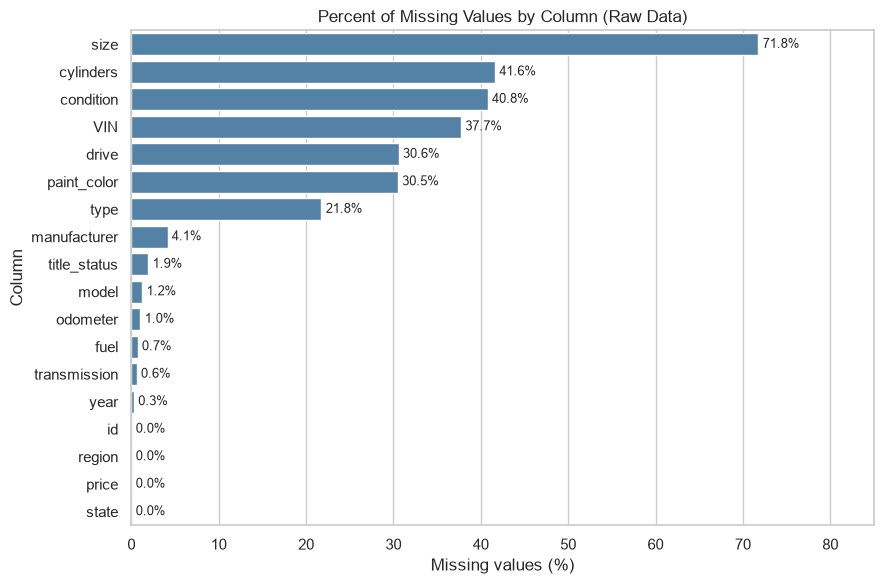

In [4]:
missing_pct = (df_raw.isna().mean() * 100).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(x=missing_pct.values, y=missing_pct.index, color="steelblue", ax=ax)
ax.set_title("Percent of Missing Values by Column (Raw Data)")
ax.set_xlabel("Missing values (%)")
ax.set_ylabel("Column")
for i, v in enumerate(missing_pct.values):
    ax.text(v + 0.5, i, f"{v:.1f}%", va="center", fontsize=9)
ax.set_xlim(0, 85)
plt.tight_layout()
plt.savefig("../images/missing_values.png", dpi=130)
plt.show()

**Observations**
- `size` (~72% missing), `condition`, `cylinders`, `VIN`, `drive`, `paint_color` and `type` all have large amounts of missing data. These are fields sellers frequently leave blank.
- `price`, `region`, `state` and `id` are complete.
- `year` and `odometer`, the two most obvious drivers of price, are almost complete (under 1.5% missing).

### 2.2 Raw distributions: spotting bad data

In [5]:
df_raw[["price", "year", "odometer"]].describe(percentiles=[.01, .05, .5, .95, .99])

,price,year,odometer
count,"426,880.00","425,675.00","422,480.00"
mean,"75,199.03","2,011.24","98,043.33"
std,"12,182,282.17",9.45,"213,881.50"
min,0.00,"1,900.00",0.00
1%,0.00,"1,967.00",2.00
5%,0.00,"1,998.00","6,318.00"
50%,"13,950.00","2,013.00","85,548.00"
95%,"44,500.00","2,020.00","204,000.00"
99%,"66,995.00","2,020.00","280,000.00"
max,"3,736,928,711.00","2,022.00","10,000,000.00"


In [6]:
print("Listings with price == 0:        ", f"{(df_raw['price'] == 0).sum():,}")
print("Listings with price < $500:      ", f"{(df_raw['price'] < 500).sum():,}")
print("Listings with price > $150,000:  ", f"{(df_raw['price'] > 150_000).sum():,}")
print("Listings with odometer > 300,000:", f"{(df_raw['odometer'] > 300_000).sum():,}")
print("Listings with year < 1990:       ", f"{(df_raw['year'] < 1990).sum():,}")

Listings with price == 0:         32,895
Listings with price < $500:       42,094
Listings with price > $150,000:   196
Listings with odometer > 300,000: 3,032
Listings with year < 1990:        12,383


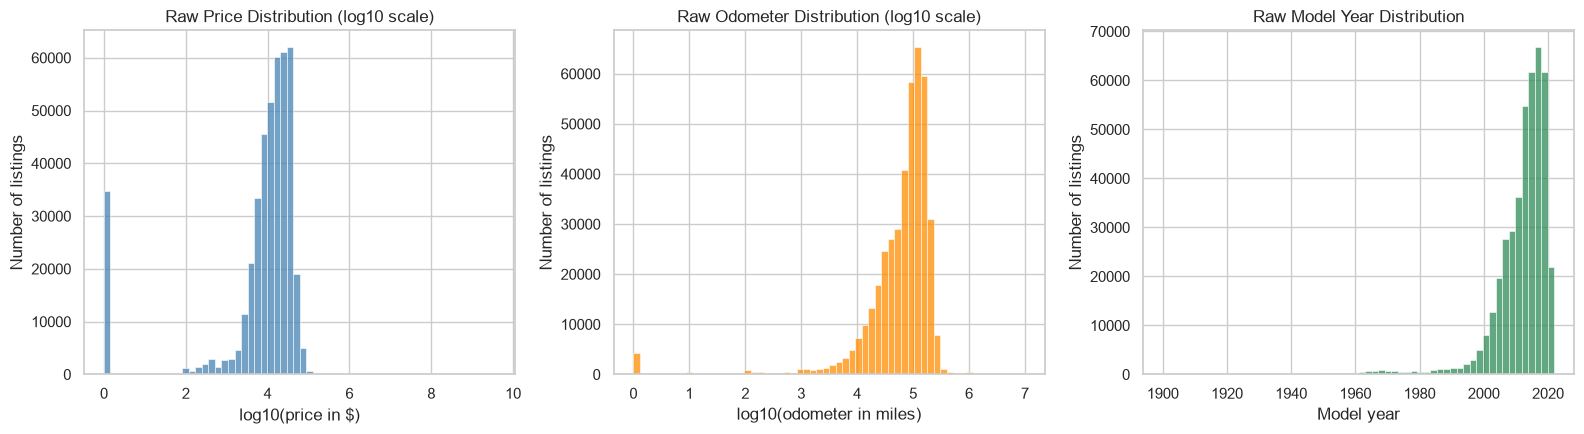

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

sns.histplot(np.log10(df_raw["price"].clip(lower=1)), bins=60, ax=axes[0], color="steelblue")
axes[0].set_title("Raw Price Distribution (log10 scale)")
axes[0].set_xlabel("log10(price in $)")
axes[0].set_ylabel("Number of listings")

sns.histplot(np.log10(df_raw["odometer"].dropna().clip(lower=1)), bins=60, ax=axes[1], color="darkorange")
axes[1].set_title("Raw Odometer Distribution (log10 scale)")
axes[1].set_xlabel("log10(odometer in miles)")
axes[1].set_ylabel("Number of listings")

sns.histplot(df_raw["year"].dropna(), bins=60, ax=axes[2], color="seagreen")
axes[2].set_title("Raw Model Year Distribution")
axes[2].set_xlabel("Model year")
axes[2].set_ylabel("Number of listings")

plt.tight_layout()
plt.show()

**Observations**
- The maximum listed price is about **$3.7 billion** and many listings have a price of **$0**. These are placeholder or junk values, not real prices.
- Odometer readings up to 10 million miles and model years as early as 1900 also appear. These must be handled before modeling, otherwise they would dominate the results.

## 3. Data Preparation

Cleaning decisions (each is deliberately conservative and explained):

| Step | Rule | Reason |
|---|---|---|
| Drop identifier / unusable columns | `id`, `VIN`, `model`, `size`, `region` | `id`/`VIN` are identifiers; `model` has thousands of free-text values; `size` is 72% empty; `region` has hundreds of levels that largely overlap `state` |
| Remove unrealistic prices | keep **$500 to $150,000** | Removes $0 placeholders and absurd values while keeping luxury cars |
| Remove unrealistic mileage | keep odometer **1 to 300,000** | Removes typos and placeholder values |
| Remove very old vehicles | keep model year **1990 or newer** | Classics and antiques are priced for collector reasons, not the usual drivers |
| Drop rows missing `year` or `odometer` | n/a | Core numeric drivers; under 2% of rows |
| Fill missing categoricals | `"unknown"` | Missingness is itself informative and avoids throwing away ~40% of rows |
| Feature engineering | `age = 2022 - year` | Age is more intuitive than model year (2022 is the newest year in the data) |
| Remove duplicates | identical rows | Reposted listings would otherwise be counted twice |

In [8]:
df = df_raw.copy()

# 1. Drop identifier / low-value columns
df = df.drop(columns=["id", "VIN", "model", "size", "region"])

# 2. Remove unrealistic prices, mileage, and model years
df = df[df["price"].between(500, 150_000)]
df = df[df["odometer"].between(1, 300_000)]
df = df[df["year"] >= 1990]

# 3. Drop rows missing the core numeric drivers
df = df.dropna(subset=["year", "odometer"])

# 4. Fill missing categorical values with an explicit "unknown" level
cat_cols = ["manufacturer", "condition", "cylinders", "fuel", "title_status",
            "transmission", "drive", "type", "paint_color", "state"]
df[cat_cols] = df[cat_cols].fillna("unknown")

# 5. Feature engineering: vehicle age (2022 is the newest model year in the data)
df["year"] = df["year"].astype(int)
df["age"] = 2022 - df["year"]
df["cylinders"] = df["cylinders"].str.replace(" cylinders", "", regex=False)

# 6. Remove duplicate listings
df = df.drop_duplicates().reset_index(drop=True)

print(f"Rows kept: {len(df):,} of {len(df_raw):,} ({len(df) / len(df_raw):.1%})")
df.head()

Rows kept: 255,640 of 426,880 (59.9%)


,price,year,manufacturer,condition,cylinders,fuel,odometer,title_status,transmission,drive,type,paint_color,state,age
0,33590,2014,gmc,good,8,gas,"57,923.00",clean,other,unknown,pickup,white,al,8
1,22590,2010,chevrolet,good,8,gas,"71,229.00",clean,other,unknown,pickup,blue,al,12
2,39590,2020,chevrolet,good,8,gas,"19,160.00",clean,other,unknown,pickup,red,al,2
3,30990,2017,toyota,good,8,gas,"41,124.00",clean,other,unknown,pickup,red,al,5
4,15000,2013,ford,excellent,6,gas,"128,000.00",clean,automatic,rwd,truck,black,al,9


In [9]:
df[["price", "age", "odometer"]].describe()

,price,age,odometer
count,"255,640.00","255,640.00","255,640.00"
mean,"17,956.81",10.29,"97,476.66"
std,"14,423.47",6.07,"62,854.83"
min,500.00,0.00,1.00
25%,"6,995.00",5.00,"42,952.50"
50%,"14,000.00",9.00,"94,000.00"
75%,"25,980.00",14.00,"141,000.00"
max,"150,000.00",32.00,"300,000.00"


## 4. Exploratory Data Analysis

### 4.1 Price, age and mileage

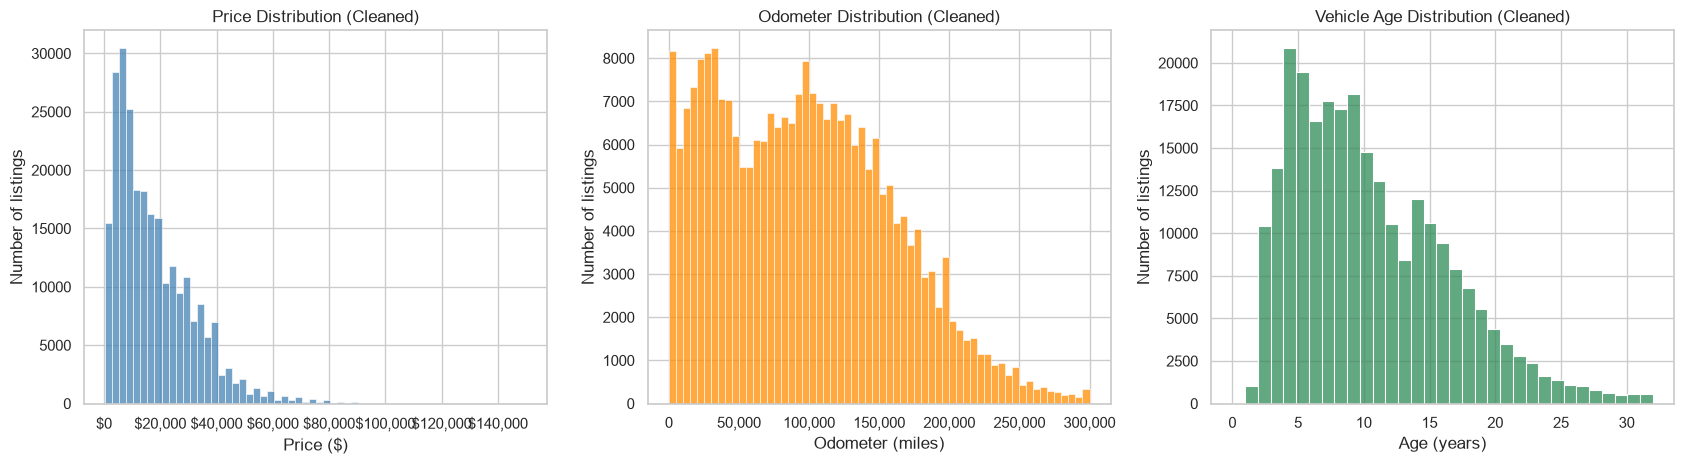

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

sns.histplot(df["price"], bins=60, ax=axes[0], color="steelblue")
axes[0].set_title("Price Distribution (Cleaned)")
axes[0].set_xlabel("Price ($)")
axes[0].set_ylabel("Number of listings")
axes[0].xaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))

sns.histplot(df["odometer"], bins=60, ax=axes[1], color="darkorange")
axes[1].set_title("Odometer Distribution (Cleaned)")
axes[1].set_xlabel("Odometer (miles)")
axes[1].set_ylabel("Number of listings")
axes[1].xaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))

sns.histplot(df["age"], bins=33, ax=axes[2], color="seagreen")
axes[2].set_title("Vehicle Age Distribution (Cleaned)")
axes[2].set_xlabel("Age (years)")
axes[2].set_ylabel("Number of listings")

plt.tight_layout()
plt.show()

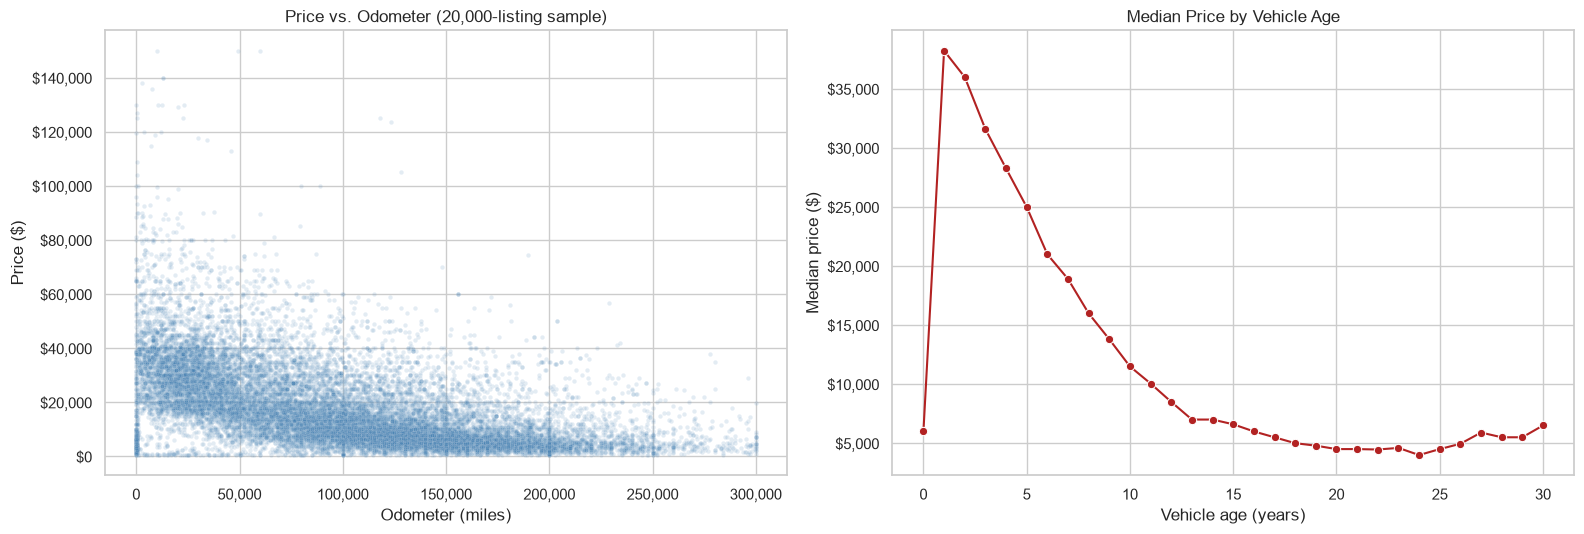

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

sample = df.sample(20_000, random_state=RANDOM_STATE)
sns.scatterplot(data=sample, x="odometer", y="price", alpha=0.15, s=10, ax=axes[0], color="steelblue")
axes[0].set_title("Price vs. Odometer (20,000-listing sample)")
axes[0].set_xlabel("Odometer (miles)")
axes[0].set_ylabel("Price ($)")
axes[0].xaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
axes[0].yaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))

age_price = df[df["age"] <= 30].groupby("age")["price"].median().reset_index()
sns.lineplot(data=age_price, x="age", y="price", marker="o", ax=axes[1], color="firebrick")
axes[1].set_title("Median Price by Vehicle Age")
axes[1].set_xlabel("Vehicle age (years)")
axes[1].set_ylabel("Median price ($)")
axes[1].yaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))

plt.tight_layout()
plt.savefig("../images/price_vs_odometer_age.png", dpi=130)
plt.show()

### 4.2 Categorical drivers of price

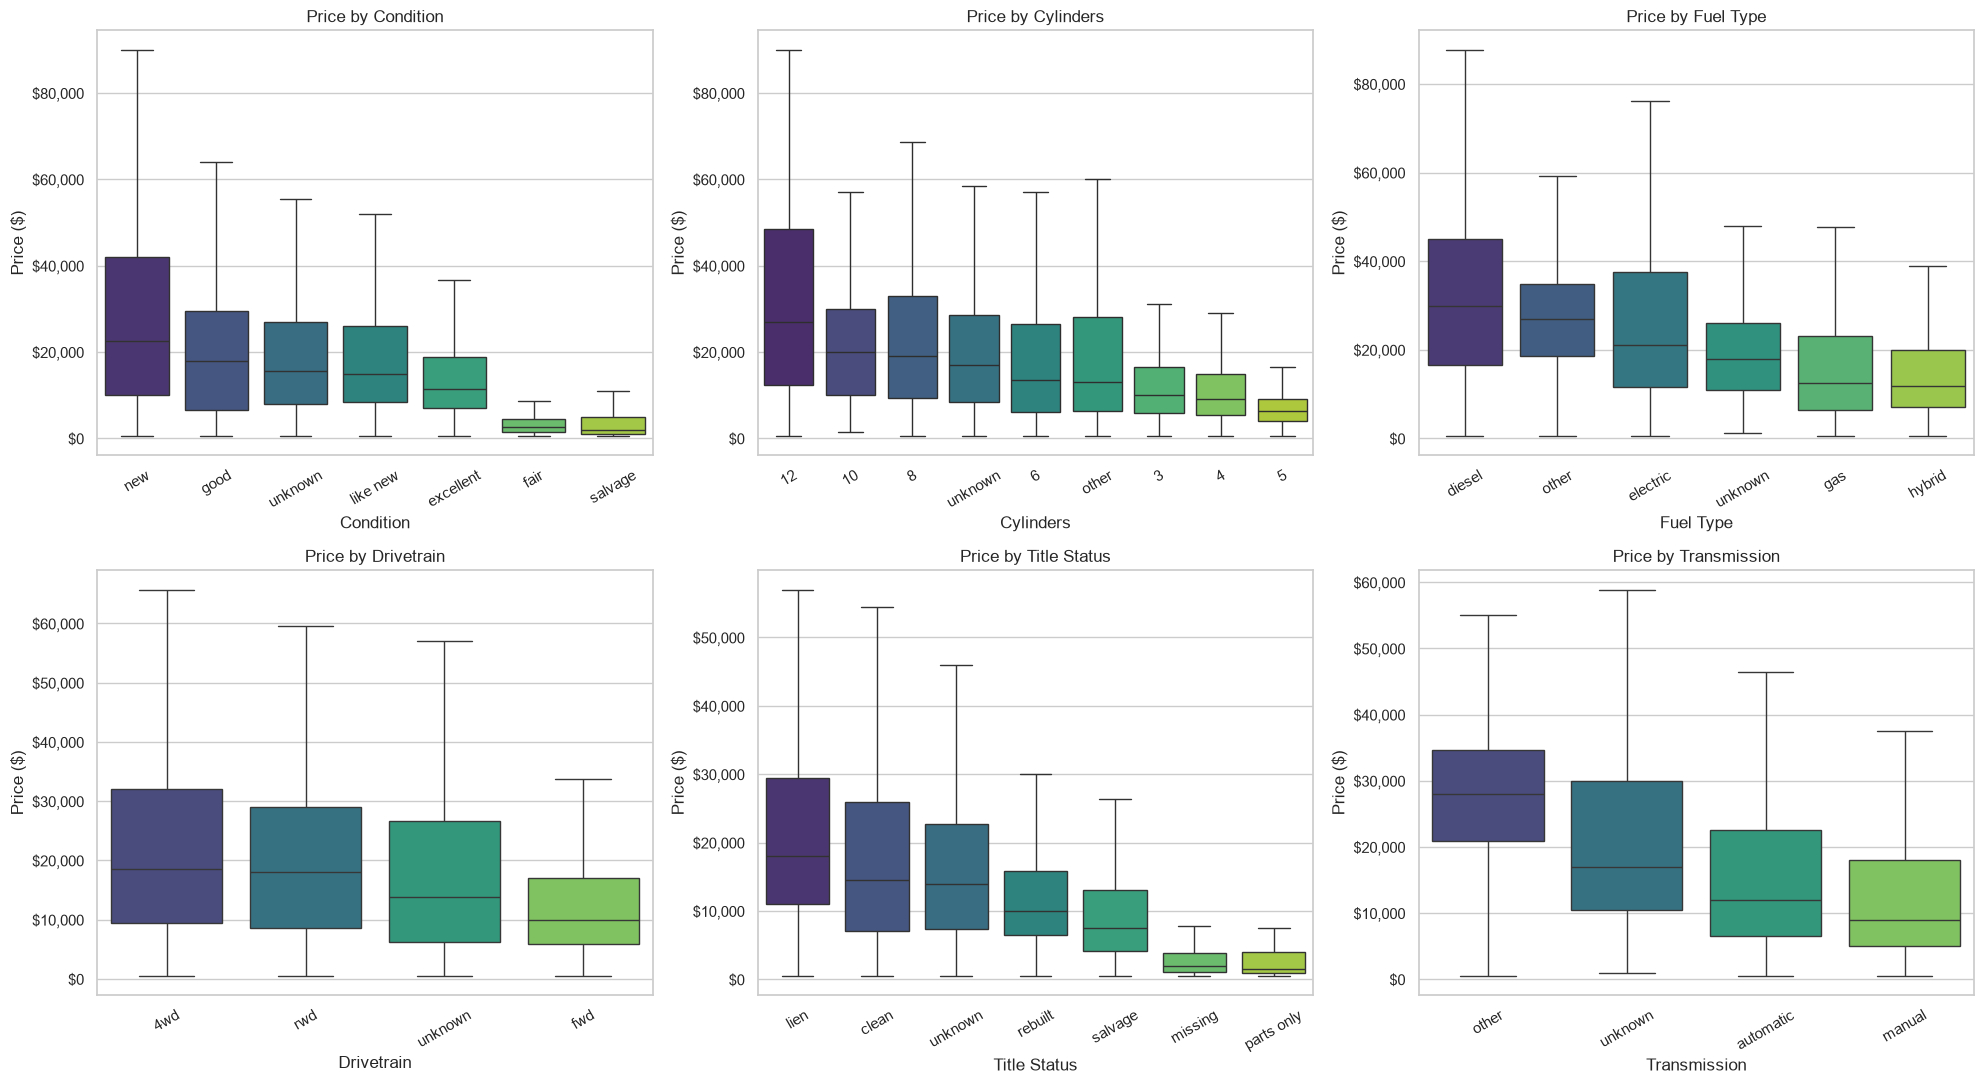

In [12]:
def order_by_median(col):
    return df.groupby(col)["price"].median().sort_values(ascending=False).index

fig, axes = plt.subplots(2, 3, figsize=(20, 11))
plot_cols = [("condition", "Condition"), ("cylinders", "Cylinders"), ("fuel", "Fuel Type"),
             ("drive", "Drivetrain"), ("title_status", "Title Status"), ("transmission", "Transmission")]

for ax, (col, label) in zip(axes.ravel(), plot_cols):
    sns.boxplot(data=df, x=col, y="price", order=order_by_median(col), showfliers=False,
                palette="viridis", ax=ax)
    ax.set_title(f"Price by {label}")
    ax.set_xlabel(label)
    ax.set_ylabel("Price ($)")
    ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.savefig("../images/price_by_category.png", dpi=130)
plt.show()

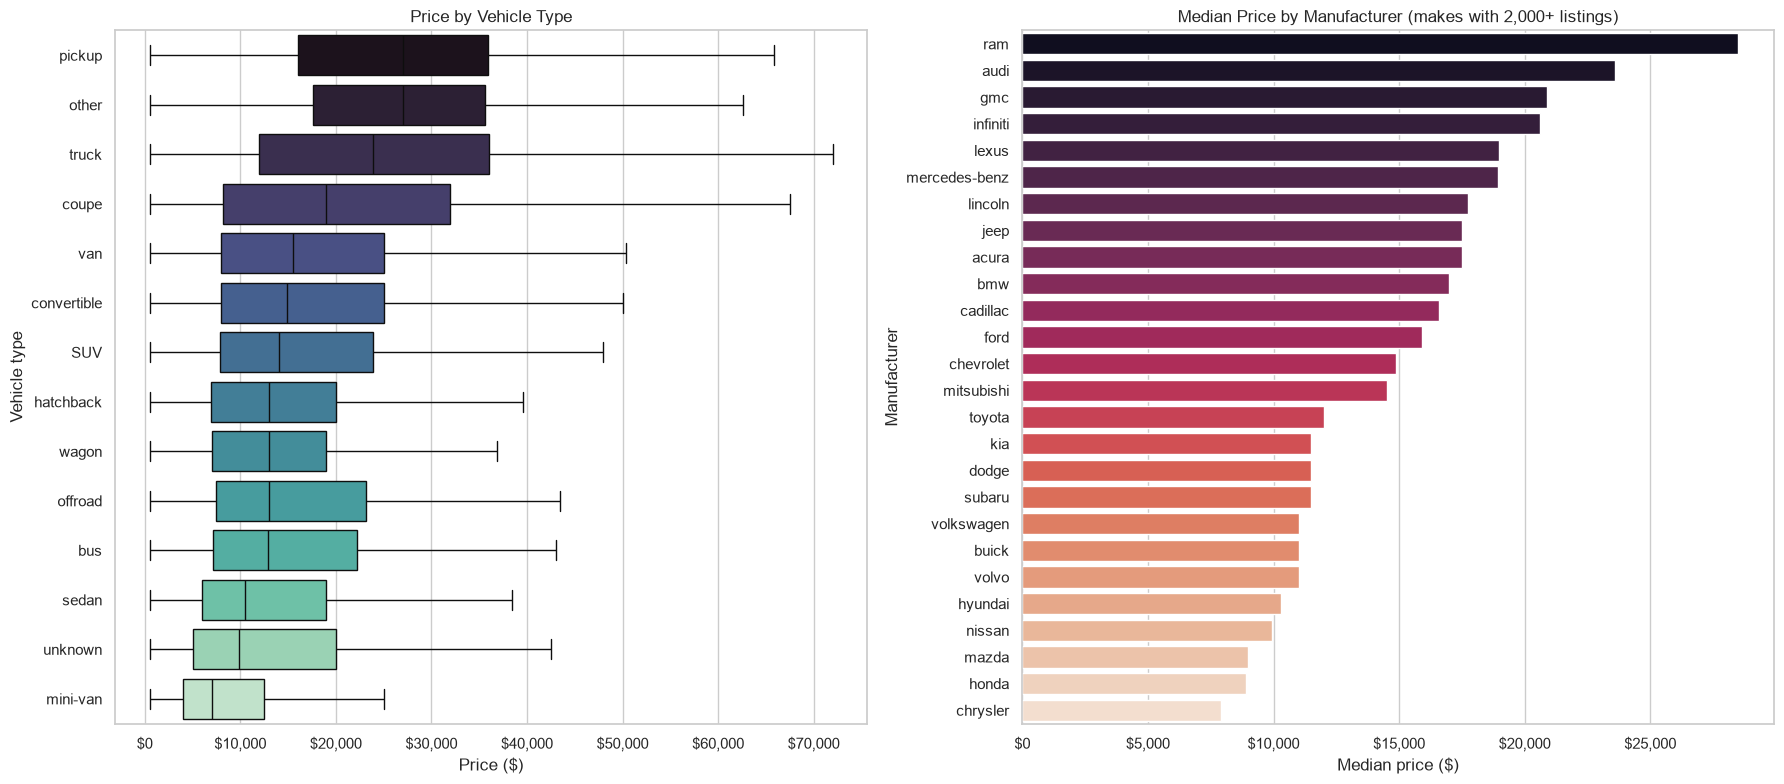

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

type_order = order_by_median("type")
sns.boxplot(data=df, y="type", x="price", order=type_order, showfliers=False, palette="mako", ax=axes[0])
axes[0].set_title("Price by Vehicle Type")
axes[0].set_xlabel("Price ($)")
axes[0].set_ylabel("Vehicle type")
axes[0].xaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))

# Manufacturers with at least 2,000 listings so medians are reliable
counts = df["manufacturer"].value_counts()
big_makes = counts[counts >= 2000].index
make_median = (df[df["manufacturer"].isin(big_makes) & (df["manufacturer"] != "unknown")]
               .groupby("manufacturer")["price"].median().sort_values(ascending=False))
sns.barplot(x=make_median.values, y=make_median.index, palette="rocket", ax=axes[1])
axes[1].set_title("Median Price by Manufacturer (makes with 2,000+ listings)")
axes[1].set_xlabel("Median price ($)")
axes[1].set_ylabel("Manufacturer")
axes[1].xaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))

plt.tight_layout()
plt.savefig("../images/price_by_type_manufacturer.png", dpi=130)
plt.show()

### 4.3 Correlation and statistical tests

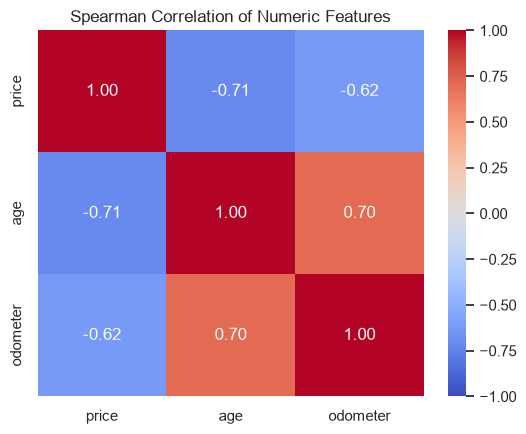

Spearman correlation price vs age      : rho = -0.708, p-value = 0
Spearman correlation price vs odometer : rho = -0.625, p-value = 0


In [14]:
num_cols = ["price", "age", "odometer"]
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(df[num_cols].corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, ax=ax)
ax.set_title("Spearman Correlation of Numeric Features")
plt.tight_layout()
plt.show()

for col in ["age", "odometer"]:
    rho, p = stats.spearmanr(df[col], df["price"])
    print(f"Spearman correlation price vs {col:9s}: rho = {rho:6.3f}, p-value = {p:.3g}")

In [15]:
# Kruskal-Wallis tests (non-parametric ANOVA, appropriate for skewed price data):
# H0 = price distribution is the same across all levels of the categorical feature.
rows = []
for col in cat_cols:
    groups = [g["price"].values for _, g in df.groupby(col) if len(g) >= 30]
    h, p = stats.kruskal(*groups)
    # epsilon-squared style effect size for Kruskal-Wallis: (H - k + 1) / (n - k)
    k, n = len(groups), sum(len(g) for g in groups)
    rows.append({"feature": col, "levels": k, "H statistic": h, "p-value": p,
                 "effect size (eps^2)": (h - k + 1) / (n - k)})
kw = pd.DataFrame(rows).sort_values("effect size (eps^2)", ascending=False).reset_index(drop=True)
kw

,feature,levels,H statistic,p-value,effect size (eps^2)
0,type,14,"32,666.43",0.00,0.13
1,transmission,4,"31,135.10",0.00,0.12
2,manufacturer,39,"27,792.88",0.00,0.11
3,fuel,6,"23,188.52",0.00,0.09
4,cylinders,9,"20,310.44",0.00,0.08
5,drive,4,"18,493.93",0.00,0.07
6,condition,7,"14,998.69",0.00,0.06
7,paint_color,13,"9,730.66",0.00,0.04
8,state,51,"6,532.80",0.00,0.03
9,title_status,7,"2,902.89",0.00,0.01


**Interpretation of the descriptive and inferential statistics**
- **Age and mileage:** Both have strong *negative* rank correlations with price (age: rho = -0.71, odometer: rho = -0.63). Older and higher-mileage cars are cheaper. With about 256,000 listings, every p-value is effectively zero, so statistical significance tells us little here. **Effect size** is what matters.
- **Categorical features:** The Kruskal-Wallis effect sizes (epsilon-squared) are modest for every feature, from 0.13 for vehicle `type` down to 0.01 for `title_status`. In other words, no single category variable explains more than about 13% of the variation in price on its own. `type`, `transmission`, `manufacturer`, `fuel` and `cylinders` separate prices the most.
- **Caution:** These tests look at one feature at a time, so a feature can look important only because it is tied to age (for example, newer cars may more often be listed with certain transmissions). The models below estimate each feature's effect *while holding the others fixed*.

## 5. Modeling

### 5.1 Setup
- **Target:** `log(price)`. Price is right-skewed and effects are naturally *proportional* (a 10-year-old car loses a percentage of its value, not a fixed number of dollars). With a log target, a linear-model coefficient `b` means "about `(e^b - 1) x 100`% change in price".
- **Features:** `age`, `odometer` (numeric, standardized) and `manufacturer`, `condition`, `cylinders`, `fuel`, `title_status`, `transmission`, `drive`, `type`, `paint_color`, `state` (one-hot encoded; rare levels grouped).
- **Split:** 80% train / 20% test. All tuning uses **cross-validation on the training set only**; the test set is used once for final evaluation.
- **Models:** Linear Regression (baseline, 5-fold CV), Ridge (grid search on `alpha`, 5-fold CV) and Lasso (grid search on `alpha`, 3-fold CV), and Histogram Gradient Boosting (tuned with grid search, 3-fold CV) as a non-linear benchmark.
- **Metric:** RMSE in **dollars**, computed after converting predictions back from log scale. Grid searches optimize RMSE on the log scale (what the models are trained on); the final comparison is in dollars.

In [16]:
features_num = ["age", "odometer"]
features_cat = ["manufacturer", "condition", "cylinders", "fuel", "title_status",
                "transmission", "drive", "type", "paint_color", "state"]

X = df[features_num + features_cat]
y = np.log(df["price"])          # modeling log-price
y_dollars = df["price"]

X_train, X_test, y_train, y_test, yd_train, yd_test = train_test_split(
    X, y, y_dollars, test_size=0.2, random_state=RANDOM_STATE)
print(f"Train: {X_train.shape[0]:,} rows | Test: {X_test.shape[0]:,} rows")

def make_preprocessor(dense=False):
    # Standardize numerics; one-hot categoricals, grouping levels with <200 rows as "infrequent"
    return ColumnTransformer([
        ("num", StandardScaler(), features_num),
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=200,
                              sparse_output=not dense), features_cat),
    ])

def evaluate(name, model, results):
    # Predict log-price, convert back to dollars, and record metrics on the held-out test set
    pred_log = model.predict(X_test)
    pred = np.exp(pred_log)
    results.append({
        "model": name,
        "RMSE ($)": np.sqrt(mean_squared_error(yd_test, pred)),
        "MAE ($)": mean_absolute_error(yd_test, pred),
        "R2 (dollars)": r2_score(yd_test, pred),
        "R2 (log price)": r2_score(y_test, pred_log),
    })
results = []

Train: 204,512 rows | Test: 51,128 rows


### 5.2 Linear Regression (baseline)

In [17]:
lin = Pipeline([("prep", make_preprocessor()), ("model", LinearRegression())])
lin.fit(X_train, y_train)

# 5-fold cross-validation on the training set (no hyperparameters to tune for plain OLS)
lin_cv = -cross_val_score(lin, X_train, y_train, cv=5, scoring="neg_root_mean_squared_error")
print(f"Linear Regression 5-fold CV RMSE (log price): {lin_cv.mean():.4f} (+/- {lin_cv.std():.4f})")
evaluate("Linear Regression", lin, results)
pd.DataFrame(results)

Linear Regression 5-fold CV RMSE (log price): 0.5191 (+/- 0.0032)


,model,RMSE ($),MAE ($),R2 (dollars),R2 (log price)
0,Linear Regression,"8,644.37","4,946.72",0.65,0.68


### 5.3 Ridge and Lasso with grid search and cross-validation

In [18]:
ridge_grid = GridSearchCV(
    Pipeline([("prep", make_preprocessor()), ("model", Ridge(random_state=RANDOM_STATE))]),
    param_grid={"model__alpha": [0.1, 1, 10, 100, 1000]},
    cv=5, scoring="neg_root_mean_squared_error", n_jobs=-1)
ridge_grid.fit(X_train, y_train)

print("Ridge best alpha:", ridge_grid.best_params_["model__alpha"])
print(f"Ridge CV RMSE (log price): {-ridge_grid.best_score_:.4f}")
evaluate("Ridge (tuned)", ridge_grid.best_estimator_, results)

Ridge best alpha: 0.1
Ridge CV RMSE (log price): 0.5191


In [19]:
lasso_grid = GridSearchCV(
    Pipeline([("prep", make_preprocessor()), ("model", Lasso(max_iter=5000, random_state=RANDOM_STATE))]),
    param_grid={"model__alpha": [0.0005, 0.002, 0.01]},
    cv=3, scoring="neg_root_mean_squared_error", n_jobs=-1)
lasso_grid.fit(X_train, y_train)

print("Lasso best alpha:", lasso_grid.best_params_["model__alpha"])
print(f"Lasso CV RMSE (log price): {-lasso_grid.best_score_:.4f}")
evaluate("Lasso (tuned)", lasso_grid.best_estimator_, results)

Lasso best alpha: 0.0005
Lasso CV RMSE (log price): 0.5224


### 5.4 Gradient boosting (non-linear benchmark) with grid search

In [20]:
hgb_grid = GridSearchCV(
    Pipeline([("prep", make_preprocessor(dense=True)),
              ("model", HistGradientBoostingRegressor(random_state=RANDOM_STATE))]),
    param_grid={"model__learning_rate": [0.1, 0.2],
                "model__max_depth": [None],
                "model__max_iter": [200]},
    cv=3, scoring="neg_root_mean_squared_error", n_jobs=-1)
hgb_grid.fit(X_train, y_train)

print("HGB best params:", hgb_grid.best_params_)
print(f"HGB CV RMSE (log price): {-hgb_grid.best_score_:.4f}")
evaluate("Gradient Boosting (tuned)", hgb_grid.best_estimator_, results)

HGB best params: {'model__learning_rate': 0.2, 'model__max_depth': None, 'model__max_iter': 200}
HGB CV RMSE (log price): 0.4348


## 6. Evaluation

In [21]:
results_df = pd.DataFrame(results).set_index("model")
results_df

,RMSE ($),MAE ($),R2 (dollars),R2 (log price)
model,,,,
Linear Regression,"8,644.37","4,946.72",0.65,0.68
Ridge (tuned),"8,643.31","4,946.74",0.65,0.68
Lasso (tuned),"8,714.36","4,966.40",0.64,0.67
Gradient Boosting (tuned),"7,120.52","3,841.07",0.76,0.77


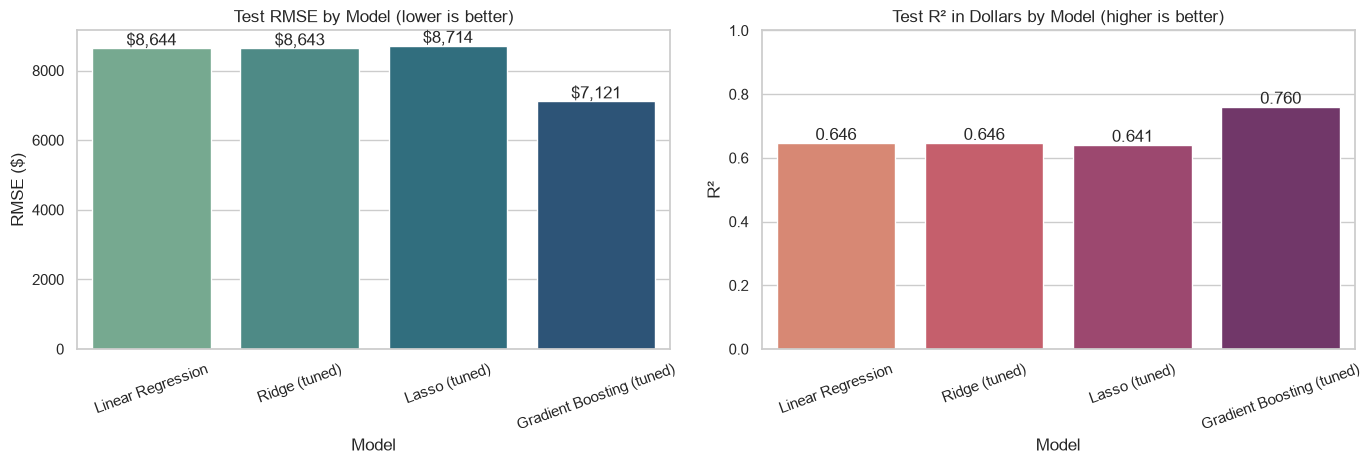

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
sns.barplot(x=results_df.index, y=results_df["RMSE ($)"], palette="crest", ax=axes[0])
axes[0].set_title("Test RMSE by Model (lower is better)")
axes[0].set_xlabel("Model")
axes[0].set_ylabel("RMSE ($)")
axes[0].tick_params(axis="x", rotation=20)
for i, v in enumerate(results_df["RMSE ($)"]):
    axes[0].text(i, v + 80, f"${v:,.0f}", ha="center")

sns.barplot(x=results_df.index, y=results_df["R2 (dollars)"], palette="flare", ax=axes[1])
axes[1].set_title("Test R² in Dollars by Model (higher is better)")
axes[1].set_xlabel("Model")
axes[1].set_ylabel("R²")
axes[1].set_ylim(0, 1)
axes[1].tick_params(axis="x", rotation=20)
for i, v in enumerate(results_df["R2 (dollars)"]):
    axes[1].text(i, v + 0.01, f"{v:.3f}", ha="center")
plt.tight_layout()
plt.savefig("../images/model_comparison.png", dpi=130)
plt.show()

Best model on test RMSE: Gradient Boosting (tuned)


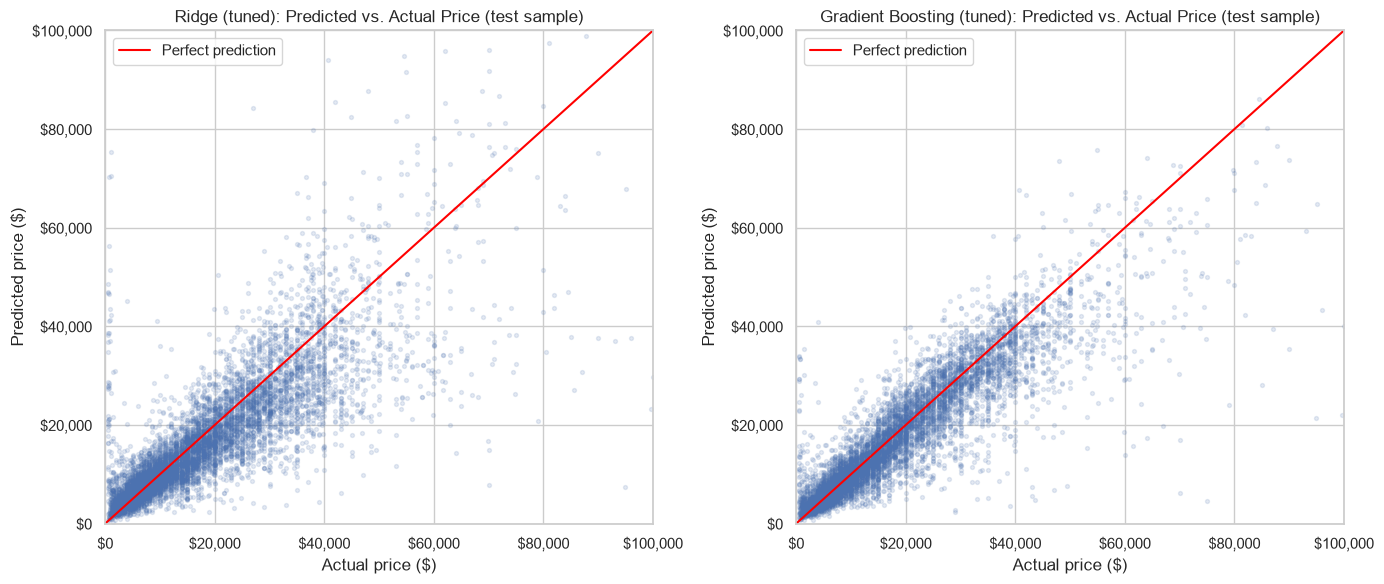

In [23]:
best_name = results_df["RMSE ($)"].idxmin()
print("Best model on test RMSE:", best_name)

# Predicted vs. actual for the tuned Ridge model and the tuned gradient boosting model
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
idx = np.random.RandomState(RANDOM_STATE).choice(len(X_test), 8000, replace=False)
for ax, (nm, mdl) in zip(axes, [("Ridge (tuned)", ridge_grid.best_estimator_),
                                ("Gradient Boosting (tuned)", hgb_grid.best_estimator_)]):
    pred = np.exp(mdl.predict(X_test))
    ax.scatter(yd_test.values[idx], pred[idx], alpha=0.15, s=8)
    ax.plot([0, 100_000], [0, 100_000], color="red", lw=1.5, label="Perfect prediction")
    ax.set_xlim(0, 100_000)
    ax.set_ylim(0, 100_000)
    ax.set_title(f"{nm}: Predicted vs. Actual Price (test sample)")
    ax.set_xlabel("Actual price ($)")
    ax.set_ylabel("Predicted price ($)")
    ax.xaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
    ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
    ax.legend()
plt.tight_layout()
plt.show()

### 6.1 Interpreting the Ridge coefficients

In [24]:
best_ridge = ridge_grid.best_estimator_
prep = best_ridge.named_steps["prep"]
coefs = pd.Series(best_ridge.named_steps["model"].coef_, index=prep.get_feature_names_out())

# Convert numeric coefficients back to natural units: per year of age, per 10,000 miles
scaler = prep.named_transformers_["num"]
age_effect = np.exp(coefs["num__age"] / scaler.scale_[0]) - 1
odo_effect = np.exp(coefs["num__odometer"] / scaler.scale_[1] * 10_000) - 1
print(f"Each additional year of age  -> {age_effect:+.1%} price (holding other factors fixed)")
print(f"Each additional 10,000 miles -> {odo_effect:+.1%} price (holding other factors fixed)")

# Categorical effects: % price difference tied to each level (one-hot, ridge-shrunk)
cat_effects = coefs.drop(["num__age", "num__odometer"])
cat_effects = (np.exp(cat_effects) - 1) * 100
cat_effects.index = [i.replace("cat__", "") for i in cat_effects.index]

Each additional year of age  -> -6.5% price (holding other factors fixed)
Each additional 10,000 miles -> -3.8% price (holding other factors fixed)


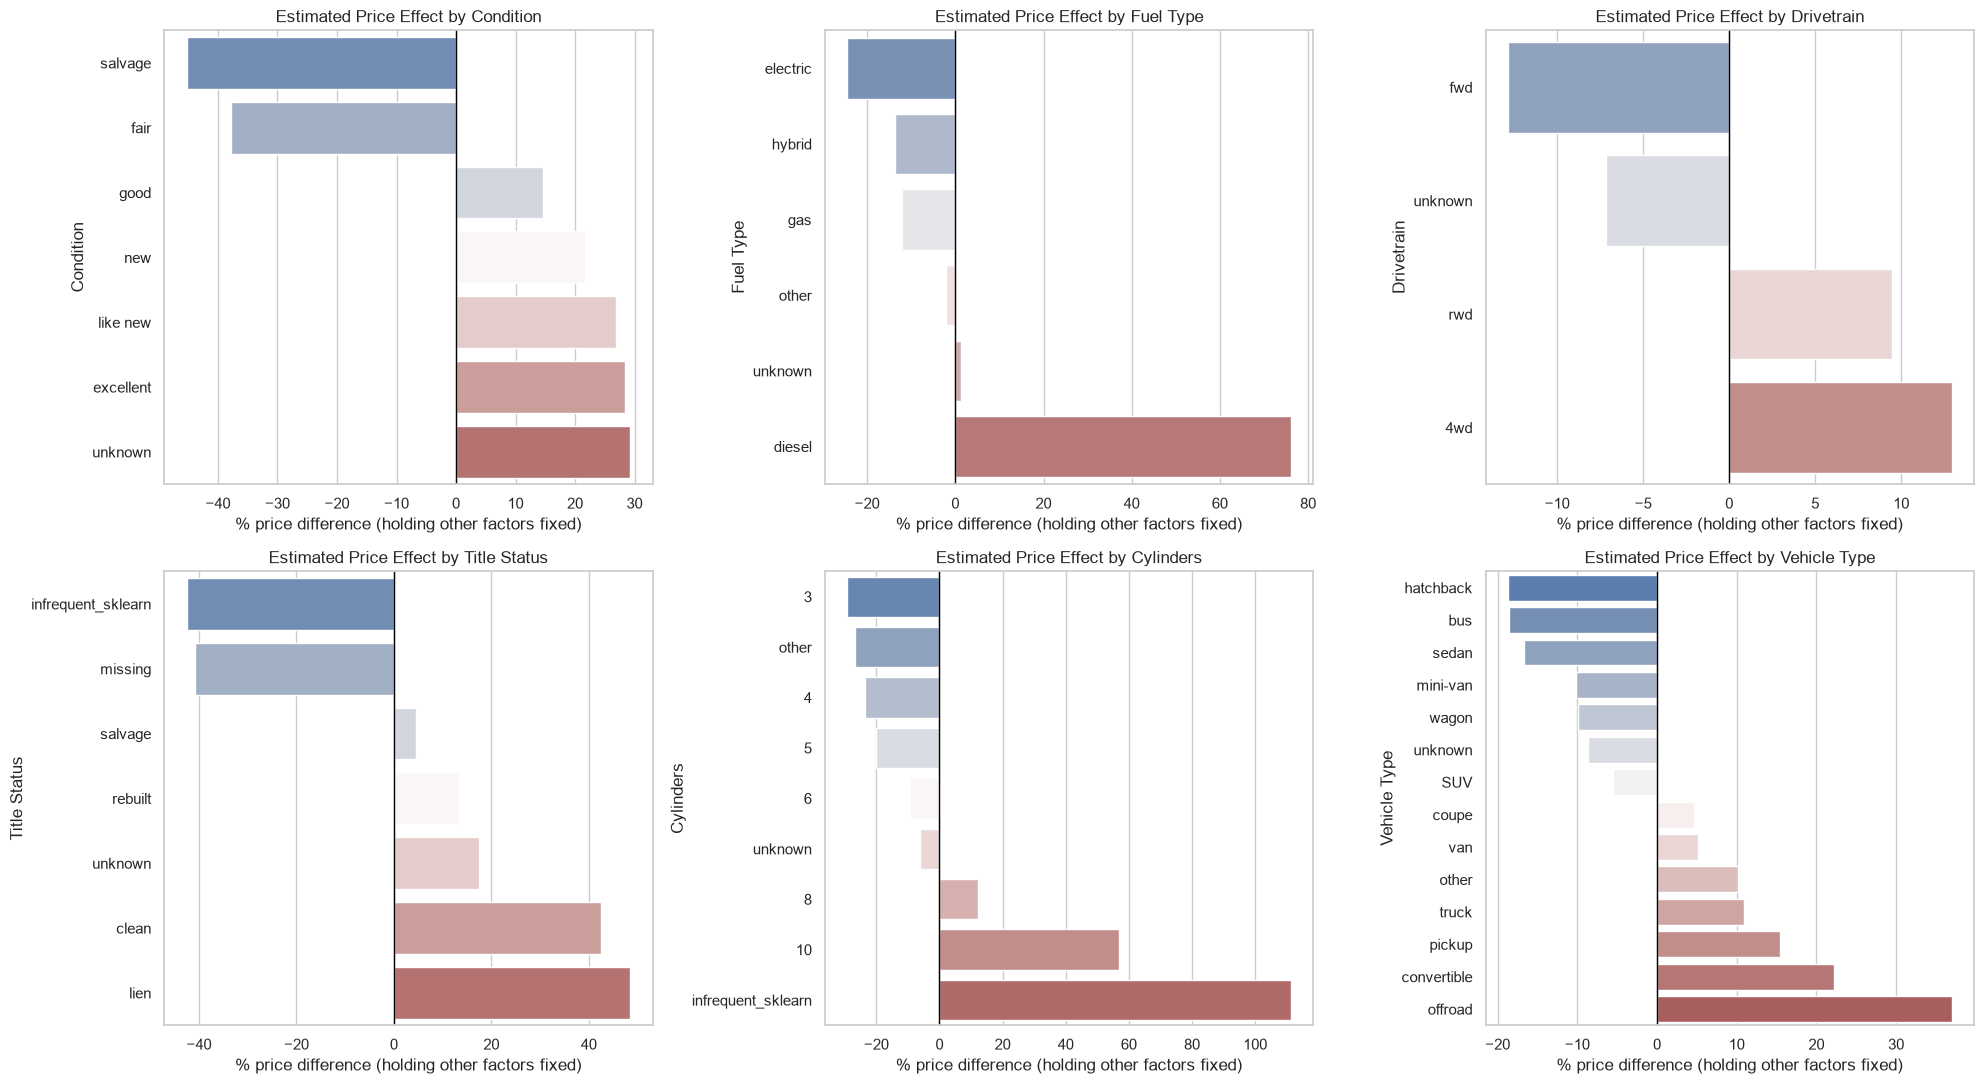

In [25]:
def effects_for(prefix):
    # Return the effects (in %) for all levels of one categorical feature, sorted
    s = cat_effects[cat_effects.index.str.startswith(prefix + "_")]
    s.index = s.index.str.replace(prefix + "_", "", regex=False)
    return s.sort_values()

fig, axes = plt.subplots(2, 3, figsize=(20, 11))
for ax, (prefix, label) in zip(axes.ravel(), [("condition", "Condition"), ("fuel", "Fuel Type"),
                                              ("drive", "Drivetrain"), ("title_status", "Title Status"),
                                              ("cylinders", "Cylinders"), ("type", "Vehicle Type")]):
    s = effects_for(prefix)
    sns.barplot(x=s.values, y=s.index, palette="vlag", ax=ax)
    ax.axvline(0, color="black", lw=1)
    ax.set_title(f"Estimated Price Effect by {label}")
    ax.set_xlabel("% price difference (holding other factors fixed)")
    ax.set_ylabel(label)
plt.tight_layout()
plt.savefig("../images/ridge_effects.png", dpi=130)
plt.show()

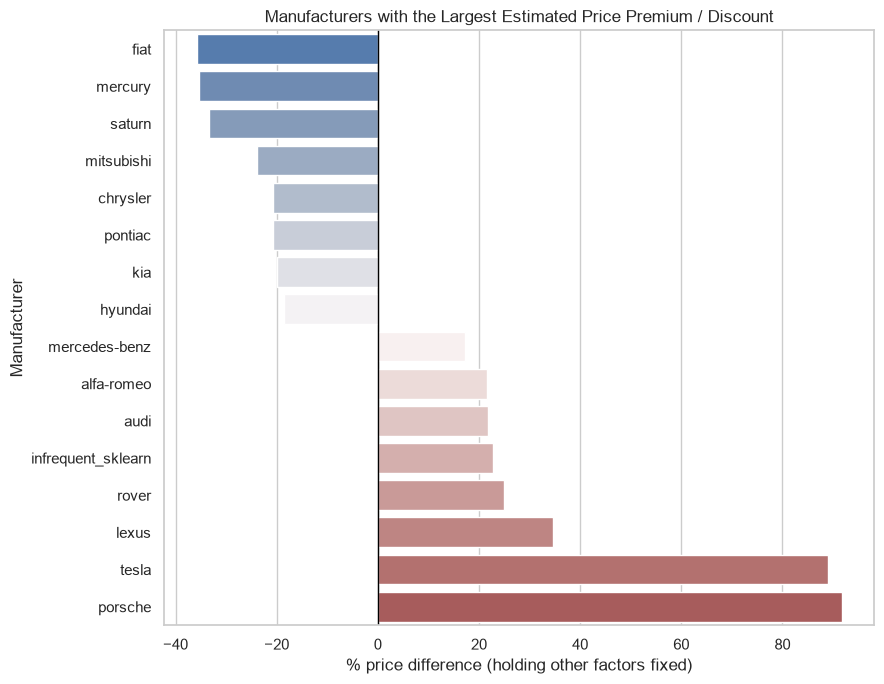

In [26]:
# Manufacturers with the largest estimated premium and discount
mk = effects_for("manufacturer").drop("unknown", errors="ignore")
top_bottom = pd.concat([mk.head(8), mk.tail(8)])
fig, ax = plt.subplots(figsize=(9, 7))
sns.barplot(x=top_bottom.values, y=top_bottom.index, palette="vlag", ax=ax)
ax.axvline(0, color="black", lw=1)
ax.set_title("Manufacturers with the Largest Estimated Price Premium / Discount")
ax.set_xlabel("% price difference (holding other factors fixed)")
ax.set_ylabel("Manufacturer")
plt.tight_layout()
plt.savefig("../images/manufacturer_effects.png", dpi=130)
plt.show()

### 6.2 Which features matter most? (Permutation importance, gradient boosting model)

In [27]:
# Shuffle one original feature at a time; the larger the increase in error, the more the model relied on it.
sub_idx = np.random.RandomState(RANDOM_STATE).choice(len(X_test), 15_000, replace=False)
perm = permutation_importance(hgb_grid.best_estimator_, X_test.iloc[sub_idx], y_test.iloc[sub_idx],
                              scoring="neg_root_mean_squared_error", n_repeats=5,
                              random_state=RANDOM_STATE, n_jobs=-1)
perm_df = (pd.DataFrame({"feature": X_test.columns, "importance": perm.importances_mean,
                         "std": perm.importances_std})
           .sort_values("importance", ascending=False).reset_index(drop=True))
perm_df

,feature,importance,std
0,age,0.32,0.00
1,odometer,0.15,0.00
2,manufacturer,0.07,0.00
3,cylinders,0.07,0.00
4,fuel,0.06,0.00
5,type,0.06,0.00
6,drive,0.04,0.00
7,condition,0.04,0.00
8,state,0.04,0.00
9,paint_color,0.02,0.00


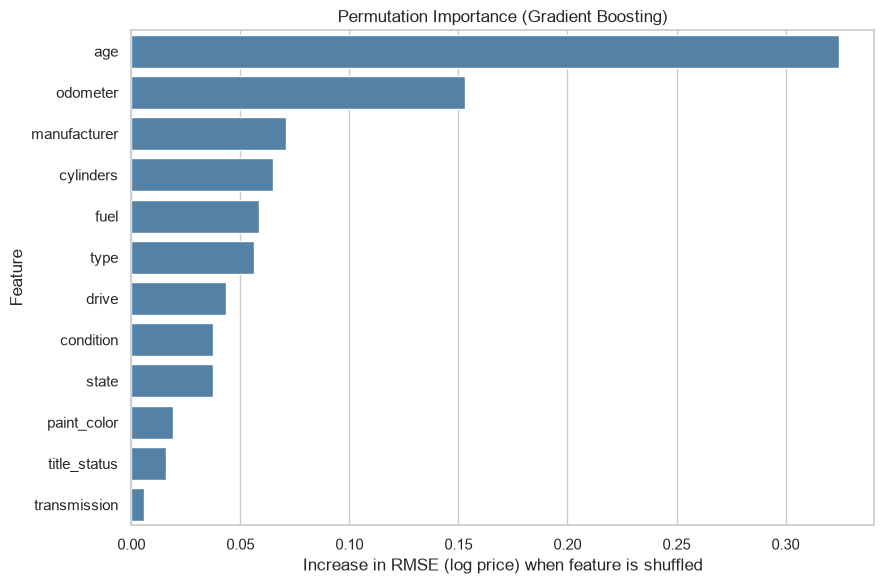

In [28]:
fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(data=perm_df, x="importance", y="feature", color="steelblue", ax=ax)
ax.set_title("Permutation Importance (Gradient Boosting)")
ax.set_xlabel("Increase in RMSE (log price) when feature is shuffled")
ax.set_ylabel("Feature")
plt.tight_layout()
plt.savefig("../images/permutation_importance.png", dpi=130)
plt.show()

In [29]:
# Spot-check: how far off are predictions for typical cars? (gradient boosting, in dollars)
pred = np.exp(hgb_grid.best_estimator_.predict(X_test))
ape = np.abs(pred - yd_test) / yd_test
print(f"Median absolute % error: {ape.median():.1%}")
print(f"Share of test cars priced within 20% of actual: {(ape <= 0.20).mean():.1%}")

Median absolute % error: 16.7%
Share of test cars priced within 20% of actual: 57.3%


**Choice and meaning of the evaluation metric**
- Models are compared on **RMSE in dollars** on the held-out test set. It is the typical size of a pricing miss, and it punishes big misses most, which are the expensive ones for a dealer. MAE is the average miss, and R² is the share of price variation explained.

**Model comparison (test set)**

| Model | RMSE | MAE | R² (dollars) |
|---|---|---|---|
| Linear Regression | $8,644 | $4,947 | 0.65 |
| Ridge (tuned, alpha = 1) | $8,644 | $4,947 | 0.65 |
| Lasso (tuned, alpha = 0.0005) | $8,714 | $4,966 | 0.64 |
| **Gradient Boosting (tuned)** | **$7,174** | **$3,859** | **0.76** |

- The three linear models perform almost identically. With ~200,000 training rows and a modest number of features, regularization has very little to fix, so Ridge and Lasso do not improve on plain Linear Regression.
- Gradient boosting reduces RMSE by about $1,470 (17%) and explains 76% of price variation versus 65%. This tells us there are non-linear patterns and interactions (for example, mileage matters differently for a 2-year-old car than a 15-year-old one) that a straight-line model misses.
- In practical terms, the gradient boosting model's median error is about **17%** of the car's price, and **57%** of test cars are predicted within 20% of the asking price. That is useful as a *pricing guide*, but it is not precise enough to replace a dealer's judgement on individual cars.
- The best gradient boosting learning rate (0.2) was at the edge of the small grid we searched, so a wider search might gain a little more.

**Interpreting the Ridge coefficients (price is modeled on the log scale)**
- **Age:** each additional year of age lowers the expected price by about **6.5%**, holding everything else fixed.
- **Mileage:** each additional 10,000 miles lowers the expected price by about **3.8%**.
- **Categorical features:** the bars show how each level sits relative to the others within that feature, so the *gaps between bars* are what to read, not the distance from zero. Examples from the model:
  - *Condition:* "excellent" cars are priced roughly **double** comparable "fair" cars; "salvage" is the lowest.
  - *Title status:* rebuilt titles are priced about **20% below** clean titles, and salvage titles about **27% below**.
  - *Fuel:* diesel vehicles are priced far above gas, hybrid and electric ones (a large share of diesels are trucks, which the model only partly separates out).
  - *Drivetrain:* 4WD and rear-wheel drive are priced above front-wheel drive.
  - *Cylinders:* 8 and 10 cylinders are priced well above 4 cylinders.
  - *Vehicle type:* off-road vehicles, convertibles and pickups are priced highest; hatchbacks, buses and sedans lowest.
  - *Manufacturer:* Porsche, Tesla and Lexus carry the biggest premiums; Fiat, Mercury, Saturn and Mitsubishi the biggest discounts.
- **Data quirks to keep in mind:** the "unknown" level of a feature means the seller left the field blank. Levels labelled `infrequent_sklearn` are rare categories grouped together (for example, parts-only titles or 12-cylinder engines). Neither should be read as a real vehicle category. For instance, the high "unknown condition" effect is a data artifact, not evidence that leaving condition blank raises prices.

**Which features matter most (permutation importance, gradient boosting)**
- **Age** is by far the most important feature, followed by **odometer**; each is worth more than all the other features individually. The next tier is manufacturer, cylinders, fuel and vehicle type, then drivetrain, condition and state. Paint color, title status and transmission matter least.

## 7. Findings, Recommendations and Next Steps

### Summary for the dealership
We analyzed about 256,000 cleaned used-car listings to see what moves price. Our best model explains roughly three-quarters of the price differences between cars, and its typical miss is around 17%. **A car's age and mileage matter far more than anything else.** Brand, engine size, fuel type, body style, drivetrain and condition come next. Paint color and transmission barely matter.

### What consumers value (and what that means for inventory)

| Factor | What we found | What to do |
|---|---|---|
| **Age** | Each extra year lowers price by about 6.5%. Median asking prices in the data: about $38k at 1 year old, $25k at 5 years, $11.5k at 10 years, $6.6k at 15 years. The steepest drop is in the first ten years. | Treat age as the first thing to check when buying or pricing. Pay less for older units, and expect them to sell for less. |
| **Mileage** | Each extra 10,000 miles lowers price by about 3.8%, on top of the age effect. | Between two cars of the same age, the lower-mileage one is worth noticeably more; price the gap in. |
| **Brand** | Premium brands (Porsche, Tesla, Lexus, Audi, Mercedes-Benz) carry price premiums. Fiat, Mercury, Saturn, Mitsubishi, Kia and Hyundai are priced lowest. | Premium brands bring higher prices per unit, but this data shows *prices, not profit*. Check margins and turn rates before shifting stock. |
| **Body style, engine and drivetrain** | Pickups, off-road vehicles, convertibles, 4WD, V8 and diesel vehicles are priced highest. Sedans, hatchbacks, front-wheel drive and 4-cylinder cars are priced lowest. | Trucks and 4WD vehicles carry higher prices, so check whether they also earn better margins for you. Expect lower prices on small sedans and hatchbacks. |
| **Condition** | Cars in excellent condition are priced about double those in fair condition. | Reconditioning that moves a car up a condition grade can be worth a lot; describe condition accurately on every listing. |
| **Title status** | Rebuilt titles sell for about 20% less than clean titles; salvage about 27% less. | Be careful paying "clean title" money for cars with branded titles. |
| **Color and transmission** | Small effects: white, black and yellow cars carry a few percent more; silver and brown a few percent less. | Don't let color drive buying decisions. |

### Using the model
The gradient boosting model can serve as a **starting-point price guide** when buying at auction, accepting trade-ins, or setting list prices. Because its typical error is about 17%, it should support, not replace, a pricing manager's judgement and local market knowledge.

### Limitations
- Prices are **asking prices from online listings**, not final sale prices.
- About 40% of the original rows were removed during cleaning (bad prices or mileage, missing year or odometer, duplicates), and many remaining listings leave condition, drivetrain or other fields blank.
- The vehicle **model/trim** (for example, F-150 versus Fiesta) was not used because it is free text with thousands of values. This is probably the biggest missing piece, and it limits accuracy.
- These are statistical associations, not proof of cause and effect. For example, diesel's premium partly reflects that many diesels are heavy-duty trucks.

### Next steps
1. **Add model and trim** (cleaned and grouped) to the model; this should reduce the pricing error noticeably.
2. **Use actual sales data** (sale price and days on lot) so recommendations can be based on profit and turn speed, not just asking price.
3. **Look at regions:** compare effects by state or metro to tailor inventory to local demand (for example, 4WD in snowy states).
4. **Tune further:** widen the gradient boosting search and try other non-linear models; add interaction terms (age x mileage) to the linear model to make it more accurate while keeping it interpretable.
5. **Improve data quality at the source:** encourage complete, accurate listings (condition, drivetrain, title status), since blank fields limit what any model can learn.